# Model comparison for video search: OpenAI CLIP baseline vs newer models (raw cosine only)
Same 1 fps frames for every model. Each model uses **its own native preprocessing** (CLIP/DFN: resize + center crop; SigLIP: whole frame resized to a square). FP16, SDPA attention where supported, one query, plain cosine ranking.
Reports per model: preprocessing time, encoder time for all frames, text-query time, GPU memory, and the top-K frames as a contact sheet so you can see which model actually returns lions.
Enable **GPU** and **Internet**. First run downloads each model (the so400m one is several GB).

In [1]:
import subprocess, sys, shutil
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "open_clip_torch", "accelerate"])
if not shutil.which("ffmpeg"): subprocess.run("apt-get update -qq && apt-get install -y -qq ffmpeg", shell=True)
FFMPEG = shutil.which("ffmpeg"); assert FFMPEG

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.9 MB/s eta 0:00:00


In [2]:
import time, gc, numpy as np, pandas as pd, torch, cv2
import matplotlib.pyplot as plt
import transformers

VIDEO_PATH = "/kaggle/input/datasets/seewhee1130/video-dataset-krishna/videoplayback.mp4"
QUERY, TEMPLATE = "lion", "{}"      # TEMPLATE = "a photo of a {}" is a free thing to try later; kept raw to match the baseline run
SAMPLE_FPS = 1
BATCH_SIZE = 32
PREP_CHUNK = 64
TOP_K, MIN_GAP_SEC = 5, 3           # contact sheet: top-K frames, at least MIN_GAP_SEC apart (avoids 5 neighbouring frames of one shot)
# Optional ground truth: fill in lion segments in seconds AFTER looking at the contact sheet, e.g. [(63, 75), (85, 95)]. Empty = skip metrics.
LION_SEGMENTS = []
assert torch.cuda.is_available(), "Enable a GPU"
print("transformers", transformers.__version__, "| torch", torch.__version__, "|", torch.cuda.get_device_name(0))

transformers 5.16.1 | torch 2.11.0+cu128 | Tesla T4


In [3]:
# ---- decode once (shared by every model; decode time is NOT part of the comparison) ----
cap = cv2.VideoCapture(VIDEO_PATH); assert cap.isOpened()
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = cap.get(cv2.CAP_PROP_FRAME_COUNT) / cap.get(cv2.CAP_PROP_FPS); cap.release()
t0 = time.time()
raw = subprocess.run([FFMPEG, "-hide_banner", "-loglevel", "error", "-nostdin", "-threads", "0", "-i", VIDEO_PATH, "-an", "-sn",
                      "-vf", f"fps={SAMPLE_FPS}", "-pix_fmt", "rgb24", "-f", "rawvideo", "-"], capture_output=True, check=True).stdout
frames = np.frombuffer(raw, np.uint8).reshape(-1, H, W, 3); del raw
timestamps = np.arange(len(frames)) / SAMPLE_FPS
print(f"{len(frames)} frames at {SAMPLE_FPS} fps, {W}x{H}, {frames.nbytes/2**30:.2f} GiB in RAM, decode {time.time()-t0:.1f}s | video {duration:.1f}s")
fmt = lambda s: f"{int(s//60)}:{int(s%60):02d}"

561 frames at 1 fps, 1280x720, 1.44 GiB in RAM, decode 28.6s | video 560.8s


In [4]:
# ---- model adapters: each returns prep(frames)->cpu tensor, img(px)->embedding, txt(str)->embedding ----
def _hf_load(cls, name):
    try:    return cls.from_pretrained(name, torch_dtype=torch.float16, attn_implementation="sdpa").cuda().eval()
    except Exception: return cls.from_pretrained(name, torch_dtype=torch.float16).cuda().eval()

def make_hf_clip(name):
    from transformers import CLIPModel, CLIPProcessor
    m, p = _hf_load(CLIPModel, name), CLIPProcessor.from_pretrained(name)
    def txt(s):
        ti = p.tokenizer([s], padding=True, return_tensors="pt").to("cuda")
        return m.text_projection(m.text_model(**ti).pooler_output)
    return dict(m=m, prep=lambda fr: p.image_processor(images=fr, return_tensors="pt")["pixel_values"],
                img=lambda px: m.visual_projection(m.vision_model(pixel_values=px).pooler_output), txt=txt, how="resize short side + center crop")

def make_hf_siglip(name):        # SigLIP / SigLIP 2 (fixed-resolution checkpoints)
    from transformers import AutoModel, AutoProcessor
    m, p = _hf_load(AutoModel, name), AutoProcessor.from_pretrained(name)
    def txt(s):                  # SigLIP expects lowercase text padded to 64 tokens (as in the HF examples); no attention mask
        ids = p.tokenizer([s.lower()], padding="max_length", max_length=64, truncation=True, return_tensors="pt")["input_ids"].cuda()
        return m.text_model(input_ids=ids).pooler_output
    return dict(m=m, prep=lambda fr: p.image_processor(images=fr, return_tensors="pt")["pixel_values"],
                img=lambda px: m.vision_model(pixel_values=px).pooler_output, txt=txt, how="whole frame resized to a square (no crop)")

def make_openclip(hub):
    import open_clip
    from PIL import Image
    m, _, pre = open_clip.create_model_and_transforms(hub, precision="fp16", device="cuda"); m.eval()
    tok = open_clip.get_tokenizer(hub)
    return dict(m=m, prep=lambda fr: torch.stack([pre(Image.fromarray(f)) for f in fr]),
                img=lambda px: m.encode_image(px), txt=lambda s: m.encode_text(tok([s]).cuda()), how="resize short side + center crop")

MODELS = [
    ("OpenAI CLIP ViT-L/14 (baseline)", lambda: make_hf_clip("openai/clip-vit-large-patch14")),
    ("DFN2B CLIP ViT-L/14 (same size)",  lambda: make_openclip("hf-hub:apple/DFN2B-CLIP-ViT-L-14")),
    ("SigLIP 2 base p16-224",            lambda: make_hf_siglip("google/siglip2-base-patch16-224")),
    ("SigLIP 2 so400m p14-384",          lambda: make_hf_siglip("google/siglip2-so400m-patch14-384")),
]

In [5]:
# ---- run every model ----
def run_model(name, factory):
    t = time.perf_counter(); M = factory(); torch.cuda.synchronize(); load_s = time.perf_counter() - t
    n_params = sum(p.numel() for p in M["m"].parameters()) / 1e6
    t = time.perf_counter(); chunks = [M["prep"](list(frames[i:i + PREP_CHUNK])).half() for i in range(0, len(frames), PREP_CHUNK)]
    px = torch.cat(chunks).cuda(); prep_s = time.perf_counter() - t; del chunks
    res = tuple(px.shape[-2:])
    with torch.inference_mode():
        M["img"](px[:BATCH_SIZE]); M["txt"]("warm up"); torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(); embs, evs = [], []
        for i in range(0, len(px), BATCH_SIZE):
            a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            a.record(); embs.append(M["img"](px[i:i + BATCH_SIZE])); b.record(); evs.append((a, b))
        torch.cuda.synchronize(); enc_ms = sum(a.elapsed_time(b) for a, b in evs); peak = torch.cuda.max_memory_allocated() / 2**20
        E = torch.cat(embs).float(); E = E / E.norm(dim=-1, keepdim=True)
        q = TEMPLATE.format(QUERY); tq = []
        for _ in range(20):
            a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            a.record(); tv = M["txt"](q); b.record(); torch.cuda.synchronize(); tq.append(a.elapsed_time(b))
        tv = tv.float(); tv = tv / tv.norm(dim=-1, keepdim=True)
        scores = (E @ tv.T).squeeze(1).cpu().numpy()
    out = dict(name=name, params_M=n_params, res=res, how=M["how"], load_s=load_s, prep_s=prep_s, enc_s=enc_ms / 1000,
               text_ms=float(np.median(tq)), peak_mib=peak, scores=scores)
    del M, px, E; gc.collect(); torch.cuda.empty_cache()
    return out

results = []
for name, factory in MODELS:
    print(f"--- {name}")
    try:
        r = run_model(name, factory); results.append(r)
        print(f"    encode {r['enc_s']:.1f}s ({r['enc_s']/len(frames)*1000:.1f} ms/frame) | prep {r['prep_s']:.1f}s | text {r['text_ms']:.1f} ms | peak {r['peak_mib']:.0f} MiB | input {r['res']}")
    except Exception as e:
        print(f"    FAILED: {type(e).__name__}: {str(e)[:300]}"); gc.collect(); torch.cuda.empty_cache()

--- OpenAI CLIP ViT-L/14 (baseline)


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

    encode 25.7s (45.9 ms/frame) | prep 5.0s | text 13.6 ms | peak 3266 MiB | input (384, 384)


                          Model Vision+text params (M) Model input                             Preprocessing CPU preprocess (s) Encode all frames (s) ms / frame Text query (ms) Peak GPU (MiB)
OpenAI CLIP ViT-L/14 (baseline)                    428     224x224           resize short side + center crop                3.8                   5.3        9.5             7.4           1253
DFN2B CLIP ViT-L/14 (same size)                    428     224x224           resize short side + center crop                7.9                   5.7       10.2             8.4           1337
          SigLIP 2 base p16-224                    375     224x224 whole frame resized to a square (no crop)                2.8                   1.4        2.5             6.3           1013
        SigLIP 2 so400m p14-384                   1136     384x384 whole frame resized to a square (no crop)                5.0                  25.7       45.9            13.6           3266

Encode time vs first model: OpenAI CLIP

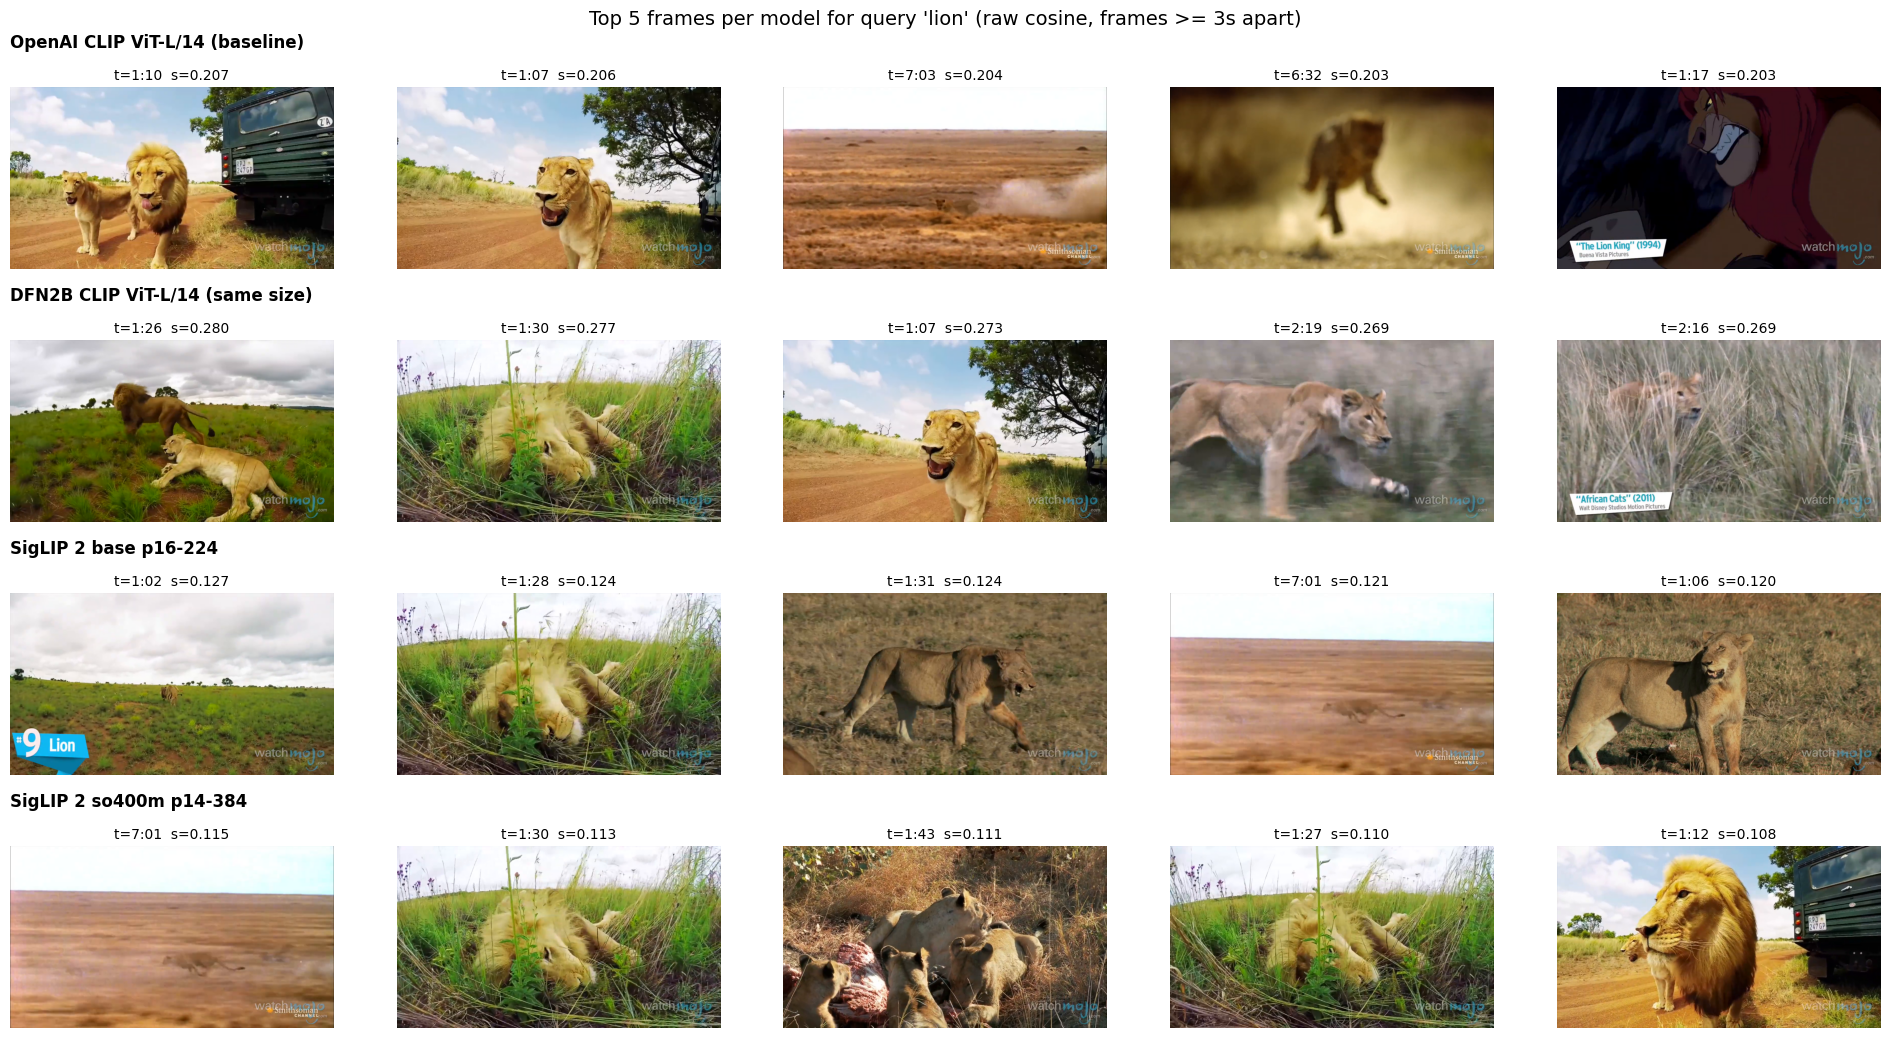

In [6]:
# ---- results: speed table, contact sheet, optional metrics ----
rows = []
rel = None
if LION_SEGMENTS: rel = np.array([any(a <= t <= b for a, b in LION_SEGMENTS) for t in timestamps]).astype(float)
def ap(scores, rel):
    r = rel[np.argsort(-scores)]; prec = np.cumsum(r) / np.arange(1, len(r) + 1); return float((prec * r).sum() / max(r.sum(), 1))
def top_k(scores):
    picked = []
    for i in np.argsort(-scores):
        if all(abs(timestamps[i] - timestamps[j]) >= MIN_GAP_SEC for j in picked): picked.append(int(i))
        if len(picked) == TOP_K: break
    return picked
for r in results:
    row = {"Model": r["name"], "Vision+text params (M)": f"{r['params_M']:.0f}", "Model input": f"{r['res'][0]}x{r['res'][1]}",
           "Preprocessing": r["how"], "CPU preprocess (s)": f"{r['prep_s']:.1f}", "Encode all frames (s)": f"{r['enc_s']:.1f}",
           "ms / frame": f"{r['enc_s']/len(frames)*1000:.1f}", "Text query (ms)": f"{r['text_ms']:.1f}", "Peak GPU (MiB)": f"{r['peak_mib']:.0f}"}
    if rel is not None:
        row["P@10 (raw top-10)"] = f"{rel[np.argsort(-r['scores'])[:10]].mean():.2f}"; row["Avg. precision"] = f"{ap(r['scores'], rel):.3f}"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
if results:
    base = results[0]["enc_s"]
    print()
    print("Encode time vs first model:", ", ".join(f"{r['name'].split(' (')[0]}: {r['enc_s']/base:.2f}x" for r in results))
    print("Note: cosine values are NOT comparable across model families (SigLIP and CLIP score on different scales); compare the rankings (the frames), not the numbers.")

fig, axes = plt.subplots(len(results), TOP_K, figsize=(3.8 * TOP_K, 2.7 * len(results))); axes = np.atleast_2d(axes)
for row_ax, r in zip(axes, results):
    for j, (ax, i) in enumerate(zip(row_ax, top_k(r["scores"]))):
        ax.imshow(frames[i]); ax.set_title(f"t={fmt(timestamps[i])}  s={r['scores'][i]:.3f}", fontsize=10); ax.axis("off")
        if j == 0: ax.text(0.0, 1.22, r["name"], transform=ax.transAxes, fontsize=12, fontweight="bold")
plt.suptitle(f"Top {TOP_K} frames per model for query {QUERY!r} (raw cosine, frames >= {MIN_GAP_SEC}s apart)", fontsize=14); plt.tight_layout()
plt.savefig("/kaggle/working/model_compare.png", dpi=100); plt.show()
np.savez("/kaggle/working/model_scores.npz", timestamps=timestamps, **{r["name"]: r["scores"] for r in results})

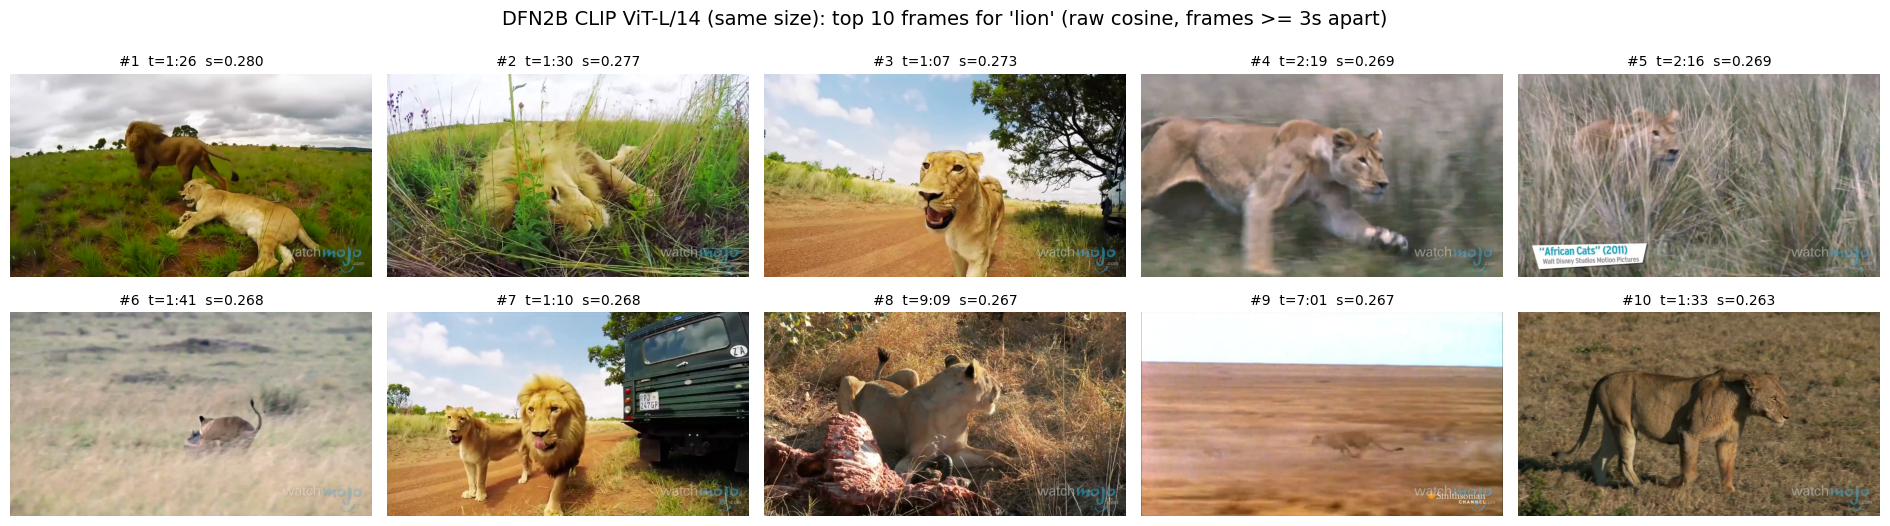

[('1:26', 0.28), ('1:30', 0.277), ('1:07', 0.273), ('2:19', 0.269), ('2:16', 0.269), ('1:41', 0.268), ('1:10', 0.268), ('9:09', 0.267), ('7:01', 0.267), ('1:33', 0.263)]


In [8]:
import math
MODEL_PREFIX, K, GAP, COLS = "DFN2B", 10, 3, 5       # change MODEL_PREFIX to "OpenAI" / "SigLIP 2 base" / "SigLIP 2 so400m" to compare
r = next(x for x in results if x["name"].startswith(MODEL_PREFIX))
picked = []
for i in np.argsort(-r["scores"]):
    if all(abs(timestamps[i] - timestamps[j]) >= GAP for j in picked): picked.append(int(i))
    if len(picked) == K: break
rows_n = math.ceil(K / COLS)
fig, axes = plt.subplots(rows_n, COLS, figsize=(3.8 * COLS, 2.8 * rows_n)); axes = np.atleast_1d(axes).ravel()
for ax, i, rank in zip(axes, picked, range(1, K + 1)):
    ax.imshow(frames[i]); ax.set_title(f"#{rank}  t={fmt(timestamps[i])}  s={r['scores'][i]:.3f}", fontsize=10); ax.axis("off")
for ax in axes[len(picked):]: ax.axis("off")
plt.suptitle(f"{r['name']}: top {K} frames for {QUERY!r} (raw cosine, frames >= {GAP}s apart)", fontsize=14); plt.tight_layout()
plt.savefig("/kaggle/working/top10.png", dpi=100); plt.show()
print([(fmt(timestamps[i]), round(float(r["scores"][i]), 3)) for i in picked])

DFN: 561 frames encoded in 13.3s (incl. preprocessing) -> (561, 768)


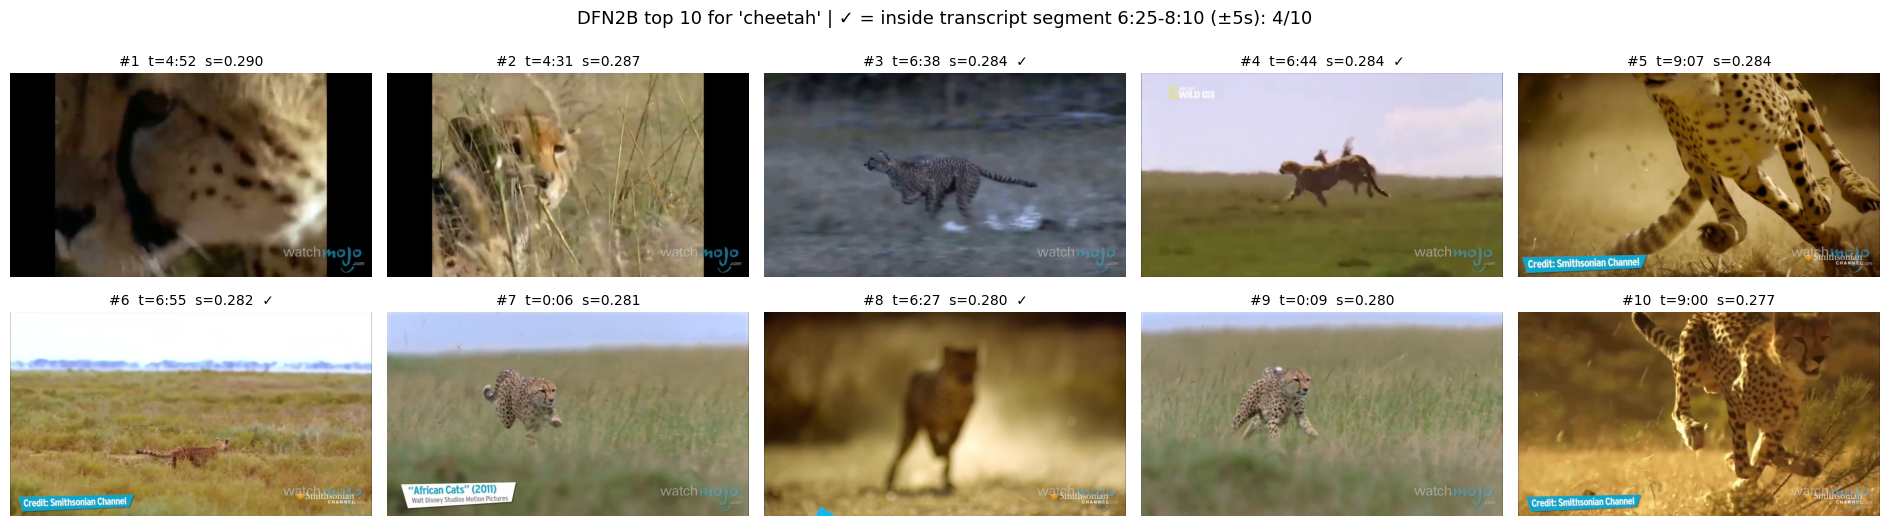

'cheetah': query took 9.4 ms | [('4:52', 0.29), ('4:31', 0.287), ('6:38', 0.284), ('6:44', 0.284), ('9:07', 0.284), ('6:55', 0.282), ('0:06', 0.281), ('6:27', 0.28), ('0:09', 0.28), ('9:00', 0.277)]


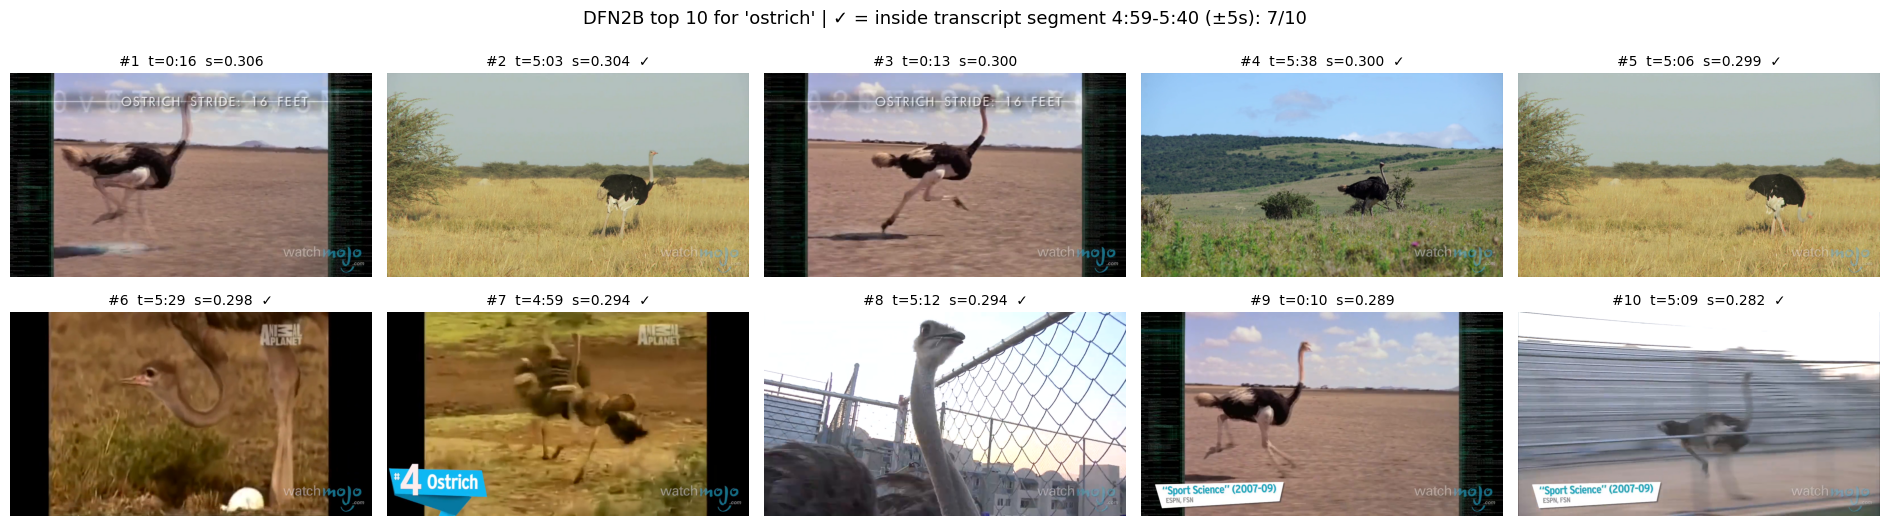

'ostrich': query took 10.1 ms | [('0:16', 0.306), ('5:03', 0.304), ('0:13', 0.3), ('5:38', 0.3), ('5:06', 0.299), ('5:29', 0.298), ('4:59', 0.294), ('5:12', 0.294), ('0:10', 0.289), ('5:09', 0.282)]


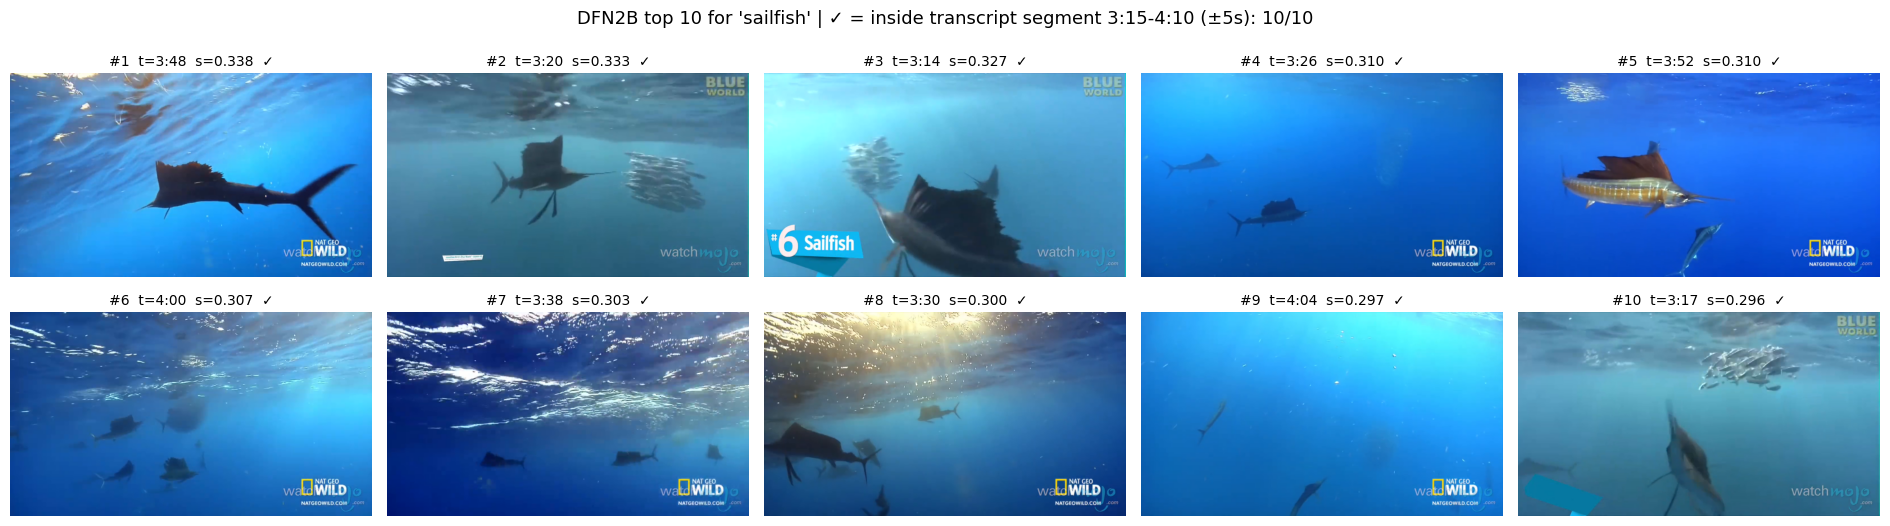

'sailfish': query took 9.7 ms | [('3:48', 0.338), ('3:20', 0.333), ('3:14', 0.327), ('3:26', 0.31), ('3:52', 0.31), ('4:00', 0.307), ('3:38', 0.303), ('3:30', 0.3), ('4:04', 0.297), ('3:17', 0.296)]


In [9]:
import math
M = make_openclip("hf-hub:apple/DFN2B-CLIP-ViT-L-14")      # stays resident, so every query below runs in milliseconds
t0 = time.perf_counter()
px = torch.cat([M["prep"](list(frames[i:i + PREP_CHUNK])).half() for i in range(0, len(frames), PREP_CHUNK)]).cuda()
with torch.inference_mode():
    E = torch.cat([M["img"](px[i:i + BATCH_SIZE]) for i in range(0, len(px), BATCH_SIZE)]).float()
    E = E / E.norm(dim=-1, keepdim=True)
del px; torch.cuda.empty_cache()
print(f"DFN: {len(E)} frames encoded in {time.perf_counter() - t0:.1f}s (incl. preprocessing) -> {tuple(E.shape)}")

# Expected segments in seconds from your transcript (animal's intro time -> next animal's intro time). Rough proxy only.
EXPECTED = {"lion": (61, 107), "sailfish": (195, 250), "ostrich": (299, 340), "cheetah": (385, 490)}
SLACK, K, GAP, COLS = 5, 10, 3, 5
NEW_QUERIES = ["cheetah", "ostrich", "sailfish"]

@torch.inference_mode()
def search(q):
    t = time.perf_counter()
    tv = M["txt"](TEMPLATE.format(q)).float(); tv = tv / tv.norm(dim=-1, keepdim=True)
    scores = (E @ tv.T).squeeze(1).cpu().numpy(); ms = (time.perf_counter() - t) * 1000
    picked = []
    for i in np.argsort(-scores):
        if all(abs(timestamps[i] - timestamps[j]) >= GAP for j in picked): picked.append(int(i))
        if len(picked) == K: break
    lo, hi = EXPECTED.get(q, (None, None))
    inside = [lo is not None and lo - SLACK <= timestamps[i] <= hi + SLACK for i in picked]
    n_rows = math.ceil(K / COLS)
    fig, axes = plt.subplots(n_rows, COLS, figsize=(3.8 * COLS, 2.8 * n_rows)); axes = np.atleast_1d(axes).ravel()
    for ax, i, ok_, rank in zip(axes, picked, inside, range(1, K + 1)):
        ax.imshow(frames[i]); ax.set_title(f"#{rank}  t={fmt(timestamps[i])}  s={scores[i]:.3f}" + ("  ✓" if ok_ else ""), fontsize=10); ax.axis("off")
    for ax in axes[len(picked):]: ax.axis("off")
    seg = f" | ✓ = inside transcript segment {fmt(lo)}-{fmt(hi)} (±{SLACK}s): {sum(inside)}/{K}" if lo is not None else ""
    plt.suptitle(f"DFN2B top {K} for {q!r}{seg}", fontsize=13); plt.tight_layout()
    plt.savefig(f"/kaggle/working/top10_{q.replace(' ', '_')}.png", dpi=100); plt.show()
    print(f"{q!r}: query took {ms:.1f} ms |", [(fmt(timestamps[i]), round(float(scores[i]), 3)) for i in picked])
    return scores

for q in NEW_QUERIES: search(q)